# Entrega de practica 1

Librerias instaladas

In [15]:
!pip install numpy
!pip install matplotlib
!pip install statistics
!pip install pandas

Notacion de las librerias instaladas

In [16]:
import statistics as sts
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Ecuaciones del metodo OLS

$$\theta_0=\bar{y}-\theta_1\bar{x}$$

$$\theta_1=\frac{\sum_{i=1}^{n}x^i(y^i-\bar{y})}{\sum_{i=1}^{n}x^i(x^i-\bar{x})}

Funcion OLS

In [17]:
def OLS (x, y):
    num = 0
    den = 0
    xMean = sts.mean(x)
    yMean = sts.mean(y)
    for i in range (len(x)):
        num += x[i] * (y[i] - yMean)
        den += x[i] * (x[i] - xMean)
    t1h = num / den
    t0h = sts.mean(y) - t1h * sts.mean(x)
    return t0h, t1h

# Funcio de obtencion de cada dataset

In [ ]:
data = []
X = []
Y = []
yMean = []
yStd = []
N = [] 

for i in range (10):
    df = pd.read_csv('dataset-{}.csv'.format(i+1))
    data.append(df)
    x = data[i]['x'].to_numpy()
    y = data[i]['y'].to_numpy()
    X.append(x)
    Y.append(y)
    yMean.append(np.mean(y))
    yStd.append(np.std(y))
    N.append(len(x))

# Lista de $\theta n_m$ para cada funcion y resultado: $\hat{y}$

In [19]:
t0h = []
t1h = []
yH = []

for i in range (10):
    a, b = OLS(X[i], Y[i])
    t0h.append(a)
    t1h.append(b)
    y_H = t0h[i] + t1h[i] * X[i]
    yH.append(y_H)

# Graficas de valores de cada dataset

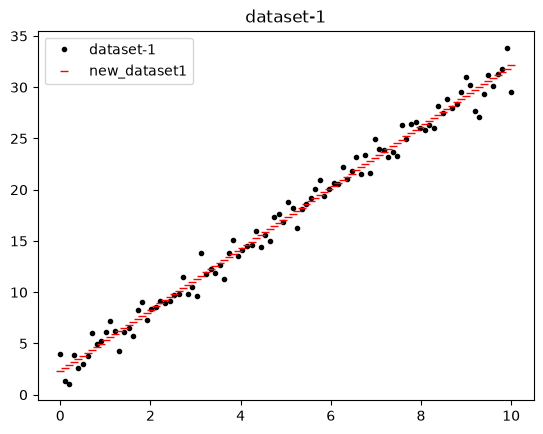

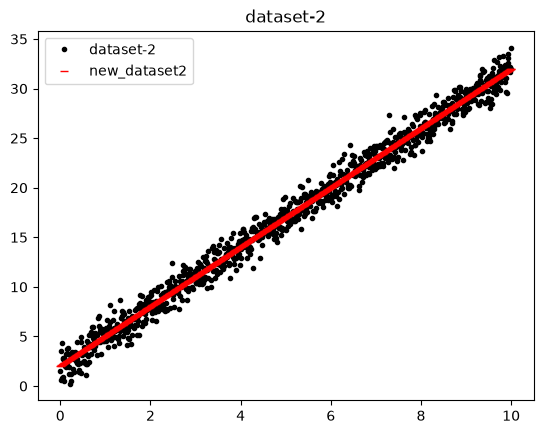

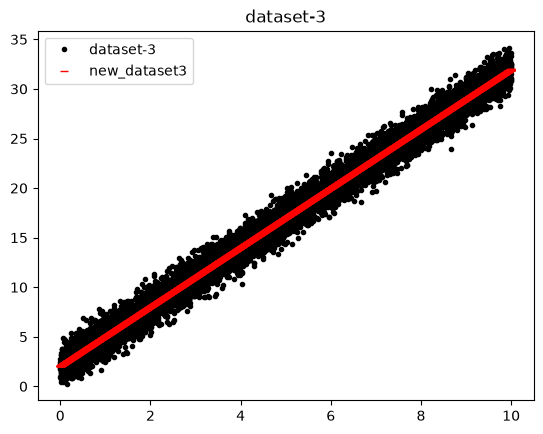

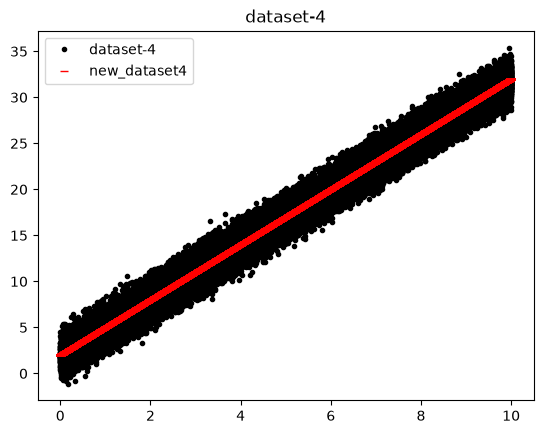

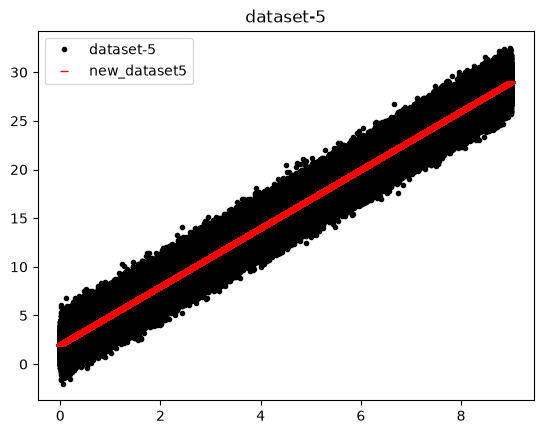

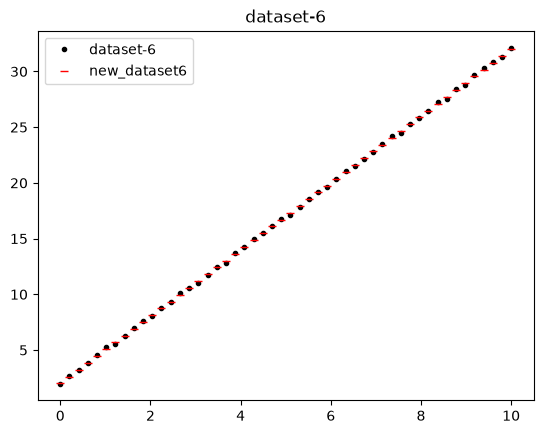

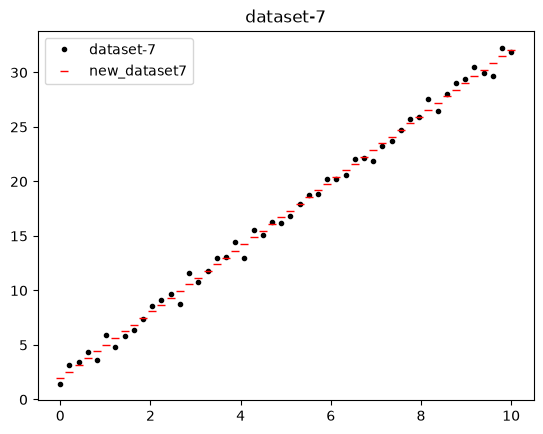

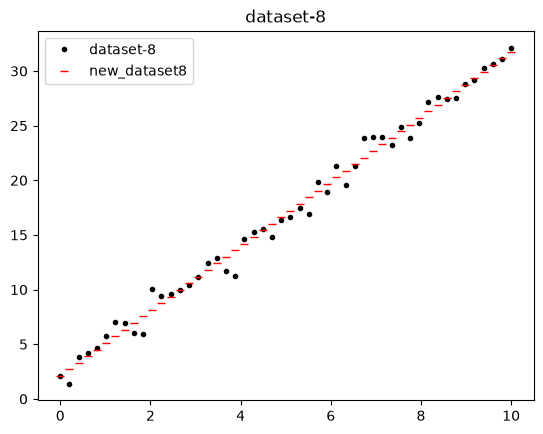

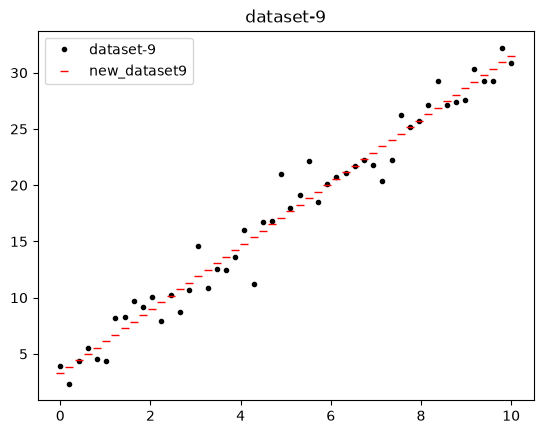

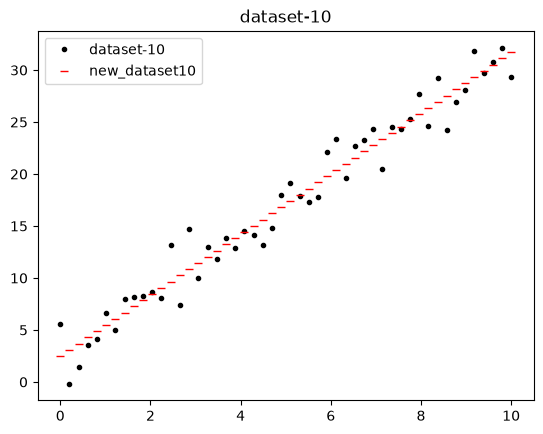

In [20]:
for i in range (10):
    plt.plot (X[i], Y[i], '.k', label = 'dataset-{}'.format(i+1))
    plt.plot (X[i], yH[i], '_r', label = 'new_dataset{}'.format(i+1))
    plt.title(f'dataset-{i+1}')
    plt.legend()
    plt.show()

# Funcion SSE

In [21]:
def func_SSE(y):
    sum = 0
    yMean = sts.mean(y)
    for i in range (len(y)):
        sum += (y[i]-yMean) ** 2
    return sum

In [22]:
SSE = []
for i in range (10):
    SSE.append(func_SSE(Y[i]))

# Graficas de Numero de puntos vs SSE de los primeros 5 datasets

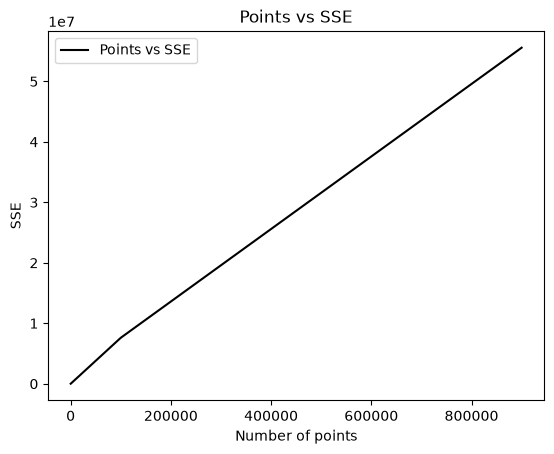

In [26]:
# points vs. SSE

plt.plot (N[0:5], SSE[0:5], '-k', label = 'Points vs SSE')
plt.legend()
plt.xlabel('Number of points')
plt.ylabel('SSE')
plt.title('Points vs SSE')
plt.show()

In [29]:
SSE[4]/900000

np.float64(61.75235513024185)

# Graficas de Dispersion vs SSE de los ultimos 5 datasets

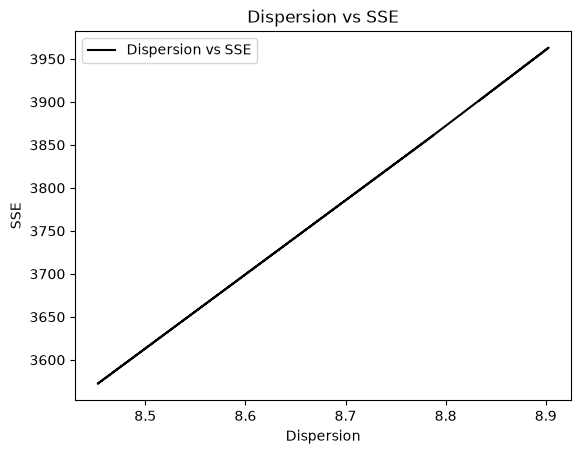

In [27]:
plt.plot (yStd[5:10], SSE[5:10], '-k', label = 'Dispersion vs SSE')
plt.legend()
plt.xlabel('Dispersion')
plt.ylabel('SSE')
plt.title('Dispersion vs SSE')
plt.show()

# Tabla de comparacion de $\theta 's$

In [25]:
print("_"*55)
print(f"|{'Num. dataset':^14}|{'theta0':^19}|{'theta1':^19}|")
print("_"*55)
for i in range(10):
    print(f"|{i+1:^14}|{t0h[i]:^19.4f}|{t1h[i]:^19.4f}|")
print("_"*55)

_______________________________________________________
| Num. dataset |      theta0       |      theta1       |
_______________________________________________________
|      1       |      2.2777       |      2.9852       |
|      2       |      2.0345       |      2.9965       |
|      3       |      2.0564       |      2.9915       |
|      4       |      1.9986       |      3.0000       |
|      5       |      2.0001       |      3.0000       |
|      6       |      2.0092       |      2.9993       |
|      7       |      1.9421       |      3.0161       |
|      8       |      2.0975       |      2.9664       |
|      9       |      3.2655       |      2.8249       |
|      10      |      2.4905       |      2.9224       |
_______________________________________________________
